# Тестовое задание на вакансию "специалист по прогнозированию спроса"

- Автор: Суздалов Дмитрий
- Дата: 12.11.2026

Для выполнения тестового задания я изначальный файл 'noname' переформатировал в .xlsx и оставил один лист с данными (задание убрал)

### Исследуем и подготавливаем данные

In [2]:
# импортируем библиотеки и правило, чтобы графики рисовались прямо тут, в тетрадке
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline 

In [3]:
#читаю файл и знакомлюсь с данными
df = pd.read_excel('data_lenta.xlsx')
print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 1016 entries, 0 to 1015
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   штуки       1016 non-null   float64
 1   week        1016 non-null   int64  
 2   year        1016 non-null   int64  
 3   promo_type  863 non-null    str    
dtypes: float64(1), int64(2), str(1)
memory usage: 31.9 KB
None
     штуки  week  year promo_type
0  13425.0     1  2023       Z008
1    753.0     1  2023       Z022
2    104.0     1  2023       Z098
3   1373.0     1  2023        NaN
4   1554.0     1  2023       Z088


Сразу замечаю, что у нас есть пропусти в колонке promo_type. Я так понимаю NaN значения означают, что промо отсутствует и товар продается по обычной цене. уберу `NaN` значения и заменю их на `Без промо`

In [4]:
df['promo_type'] = df['promo_type'].fillna('Без промо')

Создам полноценную колонку `date` для удобства будущего построения графиков:

In [5]:
df['date'] = pd.to_datetime(df['year'].astype(str) + df['week'].astype(str).str.zfill(2) + '1', format = '%Y%W%w')

Теперь я разделю данные на две части: фактические данные и прогноз на два отдельных датафрейма:

In [6]:
df_fact = df[(df['year'] < 2025) | ((df['year'] == 2025) & (df['week'] < 34))].copy()
df_forecast = df[((df['year'] == 2025) & (df['week'] >= 34))].copy()

print(f"Максимальная дата фактических продаж: {df_fact['date'].max()}")
print(f"Минимальная дата прогнозных продаж: {df_forecast['date'].min()}")

Максимальная дата фактических продаж: 2025-08-18 00:00:00
Минимальная дата прогнозных продаж: 2025-08-25 00:00:00


## Задание 1. Анализ продаж, статистический анализ, визуализация 

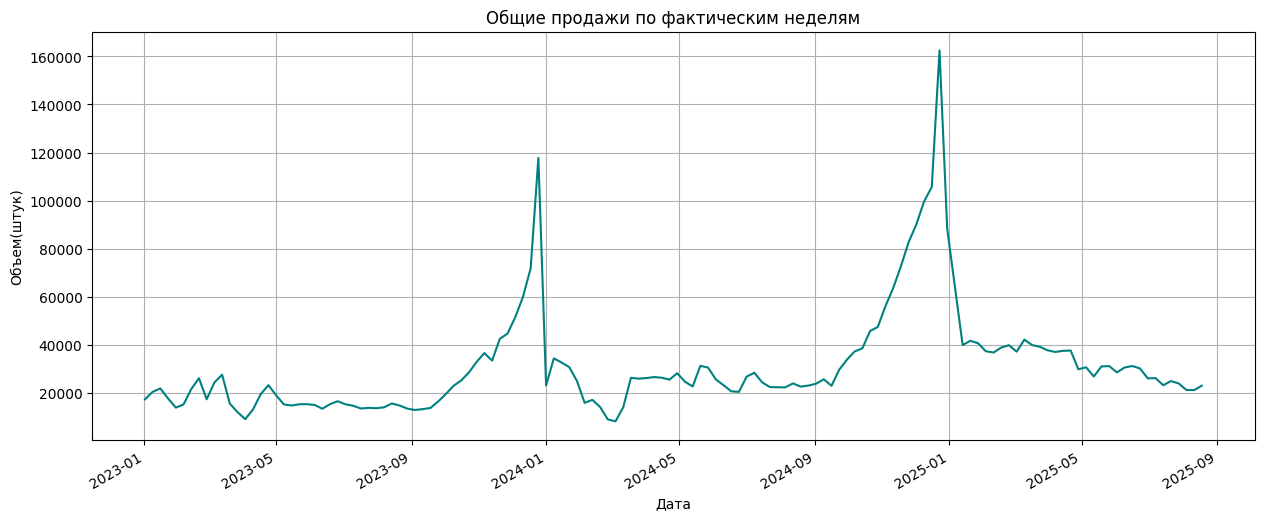

In [7]:
sales_by_week = df_fact.groupby('date')['штуки'].sum()

plt.figure(figsize= (15, 6))
sales_by_week.plot(title = "Общие продажи по фактическим неделям", grid = True, color = 'teal')
plt.xlabel('Дата')
plt.ylabel('Объем(штук)')
plt.show()

Проанализируем график:
1. Видны явные, сезонные пики роста объема продаж в конце каждого года(конец 2025 не виден, он лишь прогнозный) и последующий за этим резкий спад спроса. 
2. В целом, если смотреть на график целиком виден постепенный рост спроса на товар с течением годов. Даже новогодние пик конца 2024 года ощутимо выше пика конца 2023 года.

Основываясь на этих данных могу предположить, что эта SKU обладает относительно стабильным спросом в течение года, сезон спроса на нее приходится на конец года(новогодние праздники)

## Задание 2. Показатели истории продаж, распределение спроса. Анализ различных промо

### Начнем со среднего, медианы и моды продаж

In [8]:
mean_value = sales_by_week.mean()
median_value = sales_by_week.median()
mode_value = sales_by_week.mode()
print(f"Среднее значение: {mean_value}")
print(f"Медиана: {median_value}")
print(f"Мода: {mode_value}")

Среднее значение: 30731.861313868612
Медиана: 25441.0
Мода: 0        8087.0
1        8868.0
2        8977.0
3       11898.0
4       12796.0
         ...   
132     90100.0
133     99593.0
134    105688.0
135    117788.0
136    162512.0
Name: штуки, Length: 137, dtype: float64


В датафрейме сгруппированных по неделям фактических продаж нет дубликатов, все значения уникальны, потому моду посчитать невозможно

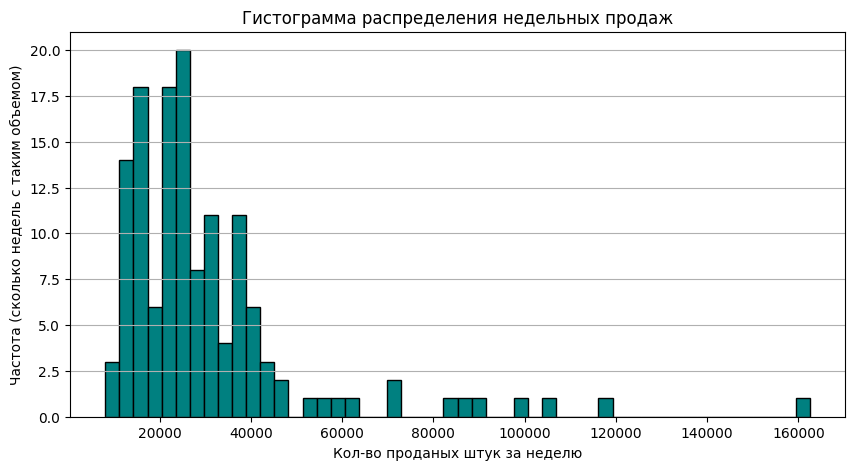

In [9]:
plt.figure(figsize = (10, 5))
sales_by_week.plot(kind = 'hist', bins = 50, title = 'Гистограмма распределения недельных продаж', color = 'teal', edgecolor = 'black')
plt.xlabel('Кол-во проданых штук за неделю')
plt.ylabel('Частота (сколько недель с таким объемом)')
plt.grid(axis = 'y')
plt.show()

Среднее значение продаж больше медианы, так произошло изза аномальных значений последних недель года, когда объемы продаж кратно растут.


### Анализ промо

Случайно выберу 3 промо и `Без промо`:

In [10]:
promos = ['Z008', 'Z039', 'Z088', 'Без промо']

df_promo = df_fact[df_fact['promo_type'].isin(promos)]

df_promo_mean = df_promo.groupby('promo_type')['штуки'].mean()
df_promo_median = df_promo.groupby('promo_type')['штуки'].median()

print(f"Средние по промо: {df_promo_mean}")
print(f"Медиана по промо: {df_promo_median}")

Средние по промо: promo_type
Z008         18723.875000
Z039         14052.439252
Z088          3524.700730
Без промо     1210.605839
Name: штуки, dtype: float64
Медиана по промо: promo_type
Z008         13813.5
Z039         11689.0
Z088          2779.0
Без промо      708.0
Name: штуки, dtype: float64


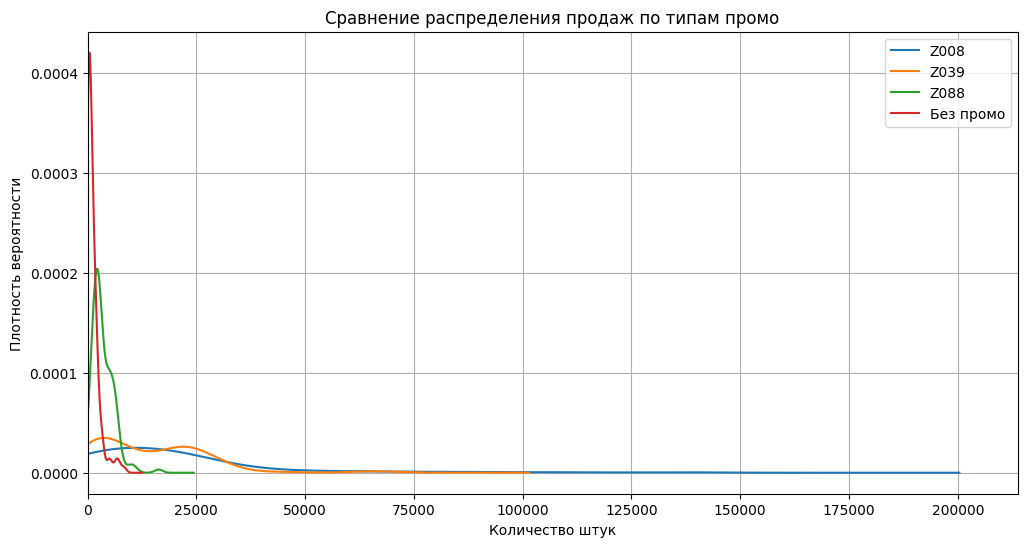

In [11]:
plt.figure(figsize = (12, 6))

for promo in promos:
    df_promo[df_promo['promo_type'] == promo]['штуки'].plot(kind = 'kde', label = promo)

plt.title('Сравнение распределения продаж по типам промо')
plt.xlabel('Количество штук')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.grid(True)
plt.xlim(left=0) 
plt.show()

При анализе `Z008`, `Z039`, `Z088` и `Без промо` можно сделать следующие выводы:
1. Средний объем продаж выше всего у промо `Z008` точно так же и медиана продаж
2. Меньше всего продаж, когда промо отсутствует

### Задание 3. Годовая сезонность товара без разделения на промо

Для начала сгруппирую данные df_fact по году и номеру недели

In [12]:
weekly_by_year = df_fact.groupby(['year', 'week'], as_index=False).agg(total_sales=('штуки', 'sum'))

#Тут я ищу среднее между 52 и 53 неделями, чтобы потом приписать это значение к 52-ой неделе и убрать 53-ю
week_52_53 = weekly_by_year[weekly_by_year['week'].isin([52, 53])].groupby('year', as_index=False).agg(total_sales=('total_sales', 'mean')).assign(week=52)

weekly_by_year_52 = pd.concat([weekly_by_year[weekly_by_year['week'] < 52],week_52_53],ignore_index=True)

seasonality = (weekly_by_year_52[weekly_by_year_52['year'].isin([2023, 2024])].groupby('week')['total_sales'].mean().reindex(range(1, 53)))

print(seasonality.tail(5))
print(f"Всего недель: {seasonality.shape[0]}")

week
48     63629.5
49     70756.0
50     79722.5
51     88732.0
52    121577.0
Name: total_sales, dtype: float64
Всего недель: 52


Для расчета сезонности я использовал только 2023 и 2024 годы, потому что они полные в отличие от 2025

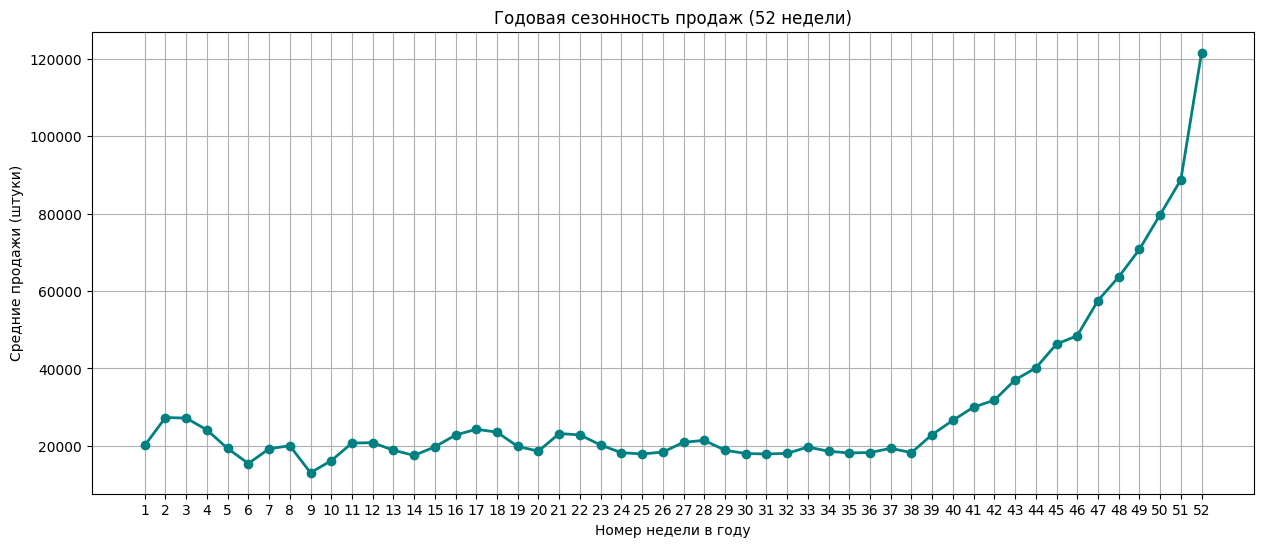

In [13]:
plt.figure(figsize = (15, 6))
seasonality.plot(kind = 'line', marker = 'o', color = 'teal', linewidth = 2)
plt.title('Годовая сезонность продаж (52 недели)')
plt.xlabel('Номер недели в году')
plt.ylabel('Средние продажи (штуки)')
plt.xticks(range(1, 53))
plt.grid(True)
plt.show()


Смотря на график можно сделать следующие выводы:
1. Существует отчетливый сезон, когда спрос на данный товар затухает (недели 22 - 38), то есть это конец мая - начало сентября. Продажи на уровне 20000.
2. Начиная с 39-ой недели спрос начинает стремительно расти и с 49-ой недели начинается взрывной рост спроса достигая пика на 52-ой недели. 

### Задание 4. Анализ прогнозных данных. Поиск несоответствий с фактом.

Для анализа я выведу обе кривые на один график и проанализирую его:

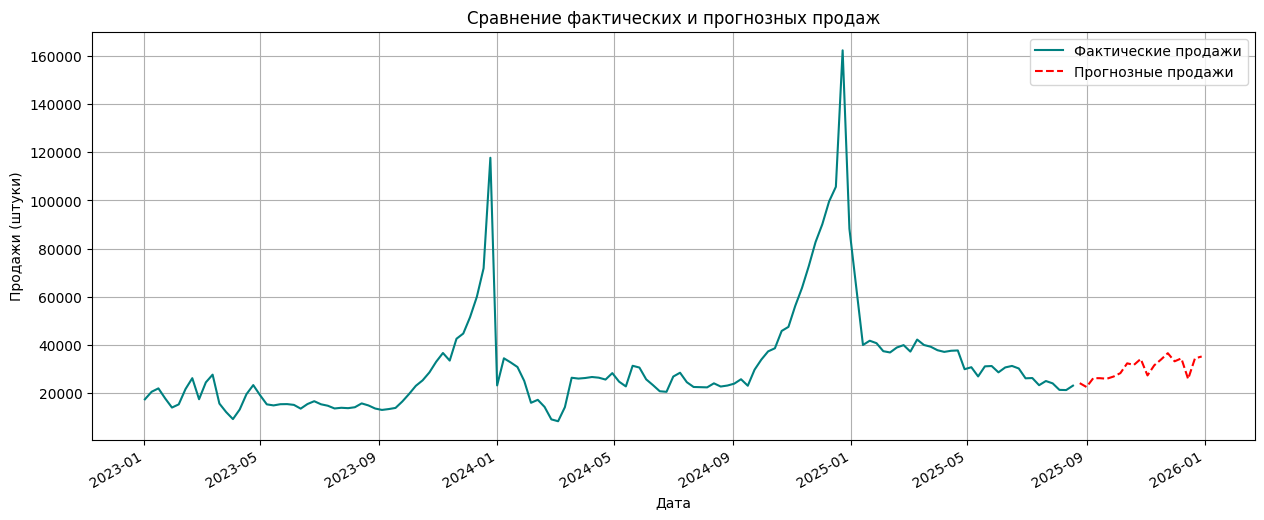

In [14]:
fact_graph = df_fact.groupby('date')['штуки'].sum()
forecast_graph = df_forecast.groupby('date')['штуки'].sum()

plt.figure(figsize = (15, 6))
fact_graph.plot(label = 'Фактические продажи', color = 'teal')
forecast_graph.plot(label = 'Прогнозные продажи', color = 'red', linestyle = '--')
plt.title('Сравнение фактических и прогнозных продаж')
plt.xlabel('Дата')
plt.ylabel('Продажи (штуки)')
plt.legend()
plt.grid(True)
plt.show()

Прогноз совсем не отражает сезонную динамику, в частности нет взрывного роста в конце года. Полагаю в данных отсутствуют некоторые промо, проверим:

In [15]:
promo_list = df_forecast['promo_type'].value_counts()
forecast_num_of_promo_per_week = df_forecast.groupby('date').size()
print(promo_list)
print(f"Количество промо в каждой неделе: {forecast_num_of_promo_per_week}")

promo_type
Z029         18
Z039         18
Без промо    16
Z008         11
Z032          4
Z023          1
Z098          1
Z088          1
Name: count, dtype: int64
Количество промо в каждой неделе: date
2025-08-25    7
2025-09-01    5
2025-09-08    5
2025-09-15    5
2025-09-22    4
2025-09-29    4
2025-10-06    4
2025-10-13    4
2025-10-20    4
2025-10-27    4
2025-11-03    4
2025-11-10    3
2025-11-17    3
2025-11-24    3
2025-12-01    3
2025-12-08    3
2025-12-15    2
2025-12-22    2
2025-12-29    1
dtype: int64


Моя гипотеза подтвердилась, с каждой неделей поличество промо акций уменьшается, а самая крупная акция `Z008` встречается всего 11 раз на 19 недель, отсюда и расхождения с фактическими данными

### Задание 5. Альтернативный прогноз. Сравнение с прошлым прогнозом

Для альтернативного прогноза я воспользуюсь сезонность, которую уже считал в задании 3. Сначала узнаю коэффициент роста продаж в 2025 году относительно известных фактических данных:

In [16]:
sales_2025 = weekly_by_year[(weekly_by_year['year'] == 2025) & (weekly_by_year['week'].between(2, 33))]

sales_previous = weekly_by_year[(weekly_by_year['year'].isin([2023, 2024])) & (weekly_by_year['week'].between(2, 33))]

mean_2025_sales = sales_2025['total_sales'].mean()
mean_previous_sales = sales_previous['total_sales'].mean()

growth_coef = mean_2025_sales / mean_previous_sales

print(f"Средние продажи в 2025: {mean_2025_sales}")
print(f"Средние продажи в 2023-2024: {mean_previous_sales}")
print(f"Коэффициент роста: {round(growth_coef, 2)}")
print(f"Рост продаж: {round(((growth_coef - 1) * 100), 2)}%")

Средние продажи в 2025: 32513.4375
Средние продажи в 2023-2024: 20134.234375
Коэффициент роста: 1.61
Рост продаж: 61.48%


In [17]:
alt_forecast_values = (seasonality.loc[34:52] * growth_coef)

forecast_weekly = (df_forecast.groupby('date')['штуки'].sum().sort_index())

alt_forecast = pd.Series(alt_forecast_values.to_numpy(),index=forecast_weekly.index)

print(alt_forecast)

date
2025-08-25     30040.748833
2025-09-01     29334.259148
2025-09-08     29497.357338
2025-09-15     31268.022344
2025-09-22     29472.327418
2025-09-29     37016.829840
2025-10-06     42948.113529
2025-10-13     48452.273739
2025-10-20     51338.788739
2025-10-27     59821.509463
2025-11-03     64775.818844
2025-11-10     74757.105117
2025-11-17     78249.182704
2025-11-24     92923.982738
2025-12-01    102751.052405
2025-12-08    114259.163815
2025-12-15    128738.568987
2025-12-22    143287.412003
2025-12-29    196326.620487
dtype: float64


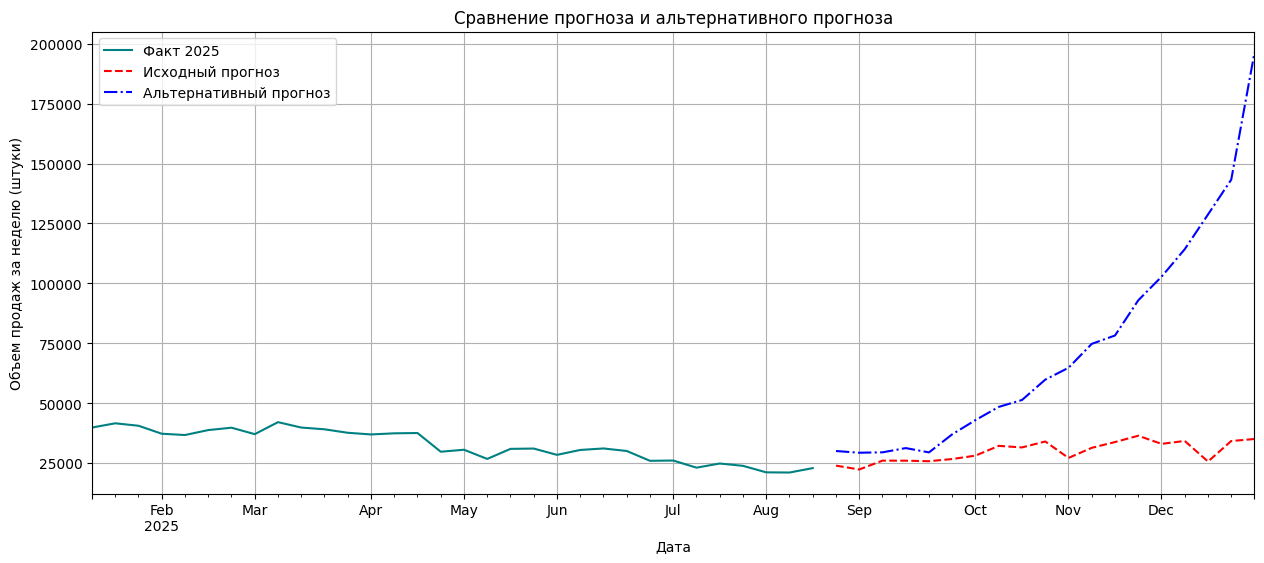

In [18]:
plt.figure(figsize = (15, 6))
df_2025_fact = df_fact[df_fact['year'] == 2025].groupby('date')['штуки'].sum()
df_2025_fact.plot(label = 'Факт 2025', color = 'teal')
df_forecast.groupby('date')['штуки'].sum().plot(label='Исходный прогноз', color='red', linestyle='--')
alt_forecast.plot(label = 'Альтернативный прогноз', color = 'blue', linestyle = '-.')

plt.title('Сравнение прогноза и альтернативного прогноза')
plt.xlabel('Дата')
plt.ylabel('Объем продаж за неделю (штуки)')
plt.legend()
plt.grid(True)
plt.show()


Выведу альтернативный прогноз на общий график:

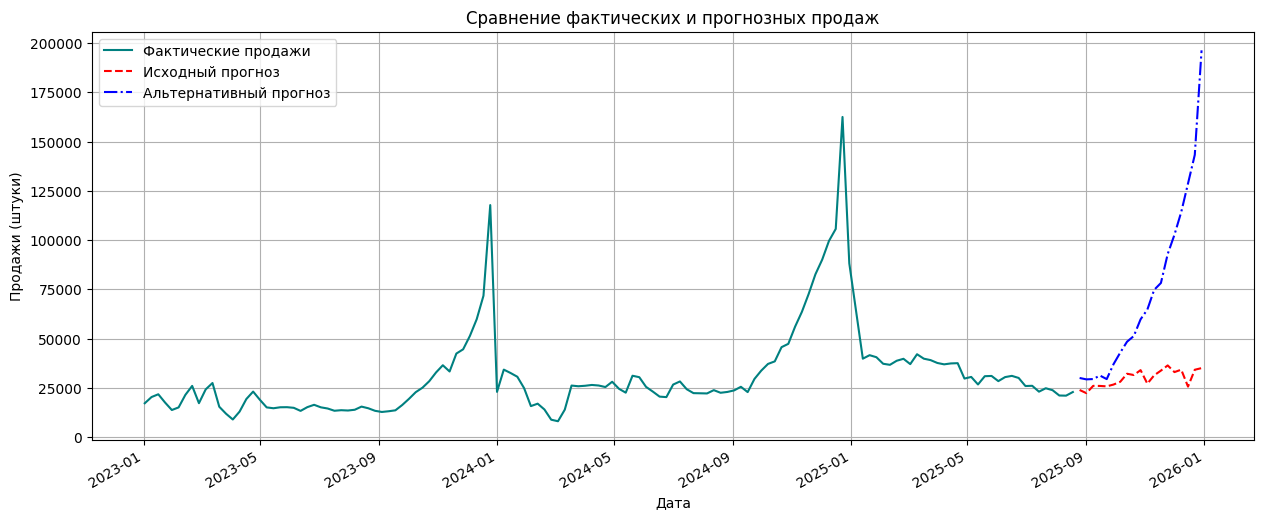

In [19]:
plt.figure(figsize = (15, 6))
fact_graph.plot(label = 'Фактические продажи', color = 'teal')
df_forecast.groupby('date')['штуки'].sum().plot(label='Исходный прогноз', color='red', linestyle='--')
alt_forecast.plot(label = 'Альтернативный прогноз', color = 'blue', linestyle = '-.')
plt.title('Сравнение фактических и прогнозных продаж')
plt.xlabel('Дата')
plt.ylabel('Продажи (штуки)')
plt.legend()
plt.grid(True)
plt.show()

Выводы (было-стало):
Альтернативный прогноз (синяя линия) гораздо лучше демонстрирует рост спроса на товар, учитывает новогодний всплеск объема, нежели изначальный прогноз (красная линия)

### Бэктест метода прогноза за 2024 год

Коэффициент роста 2024 vs 2023: 1.41

=== Метрики бэктеста на неделях 34-52 / 2024 ===
MAE  : 7,716 шт.   — средняя абсолютная ошибка
Bias : +7,398 шт. — систематическое смещение
MAPE : 15.4%      — средняя ошибка в %
WAPE : 13.5%      — взвешенная ошибка в % (стандарт ритейла)


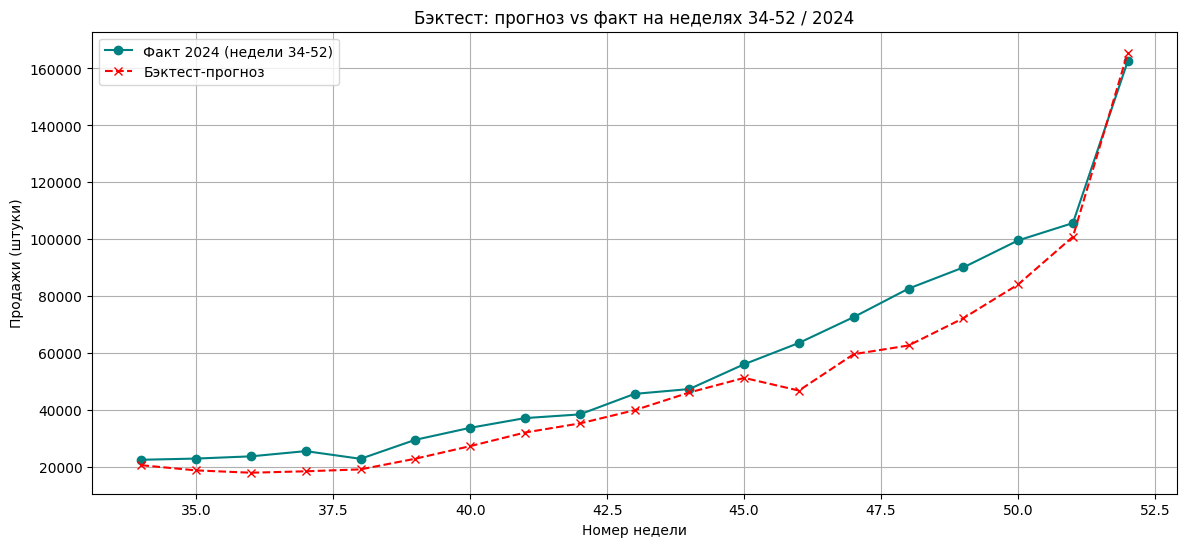

In [22]:
# =========================================================
# БЭКТЕСТ: проверяем метод прогноза на исторических данных
# Обучаемся на 2023, прогнозируем конец 2024, сравниваем с фактом
# =========================================================

# 1. Готовим факт для проверки — недели 34-52 2024 года
fact_2024_test = (df_fact[df_fact['year'] == 2024].groupby('week')['штуки'].sum().reindex(range(34, 53)))

# 2. Строим сезонный профиль по 2023 году (52 недели)
seasonality_2023 = (df_fact[df_fact['year'] == 2023].groupby('week')['штуки'].sum().reindex(range(1, 53)))

# 3. Считаем коэффициент роста: 2024 vs 2023 по сопоставимым неделям 2-33
sales_2023_train = df_fact[(df_fact['year'] == 2023) & (df_fact['week'].between(2, 33))].groupby('week')['штуки'].sum()
sales_2024_train = df_fact[(df_fact['year'] == 2024) & (df_fact['week'].between(2, 33))].groupby('week')['штуки'].sum()

growth_coef_2024 = sales_2024_train.mean() / sales_2023_train.mean()
print(f"Коэффициент роста 2024 vs 2023: {growth_coef_2024:.2f}")

# 4. Прогноз на недели 34-52 2024 = сезонность 2023 × коэффициент
backtest_forecast = seasonality_2023.loc[34:52] * growth_coef_2024

# 5. Считаем метрики
errors = fact_2024_test.values - backtest_forecast.values

mae  = abs(errors).mean()                          # средняя ошибка в штуках
bias = errors.mean()                               # смещение (+ завышаем / - занижаем)
mape = (abs(errors) / fact_2024_test.values * 100).mean()  # средняя ошибка в %
wape = abs(errors).sum() / fact_2024_test.values.sum() * 100  # взвешенная ошибка в %

print(f"\n=== Метрики бэктеста на неделях 34-52 / 2024 ===")
print(f"MAE  : {mae:,.0f} шт.   — средняя абсолютная ошибка")
print(f"Bias : {bias:+,.0f} шт. — систематическое смещение")
print(f"MAPE : {mape:.1f}%      — средняя ошибка в %")
print(f"WAPE : {wape:.1f}%      — взвешенная ошибка в % (стандарт ритейла)")

# 6. Визуализация
plt.figure(figsize=(14, 6))
fact_2024_test.plot(label='Факт 2024 (недели 34-52)', color='teal', marker='o')
backtest_forecast.plot(label='Бэктест-прогноз', color='red', marker='x', linestyle='--')
plt.title('Бэктест: прогноз vs факт на неделях 34-52 / 2024')
plt.xlabel('Номер недели')
plt.ylabel('Продажи (штуки)')
plt.legend()
plt.grid(True)
plt.show()